In [1]:
import sys

print("Python:", sys.version)
print("Interpreter:", sys.executable)
print("Jupyter Notebook is working!")

Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
Interpreter: c:\Users\Anjana\Desktop\ML\customer-churn-prediction\.venv\Scripts\python.exe
Jupyter Notebook is working!


IMPORT LIBRARIES

In [ ]:
import pandas as pd  
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns           #provides convenient statistical visualization functions

from pathlib import Path

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)   #see all DataFrame columns instead of hiding some.
pd.set_option("display.width", 120)

print("pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Libraries imported successfully")


pandas version: 3.1.0
NumPy version: 2.5.4
Libraries imported successfully


LOAD DATASET

In [8]:
DATA_PATH = Path("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

df = pd.read_csv(DATA_PATH) 

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


INSPECT THE DATASET STRUCTURE

In [12]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
df.info()


Number of rows: 7043
Number of columns: 21

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   

GENERATE DESCRIPTIVE STATISTICS

In [14]:
display(df.describe())  #statistics for numeric columns

display(df.describe(include = ["object"]))  #statistics for categorical columns

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


C:\Users\Anjana\AppData\Local\Temp\ipykernel_24156\246956336.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include = ["object"]))  #statistics for categorical columns


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


-----------------------DATA QUALITY INVESTIGATION---------------------------

CHECK MISSING VALUES
Blank strings or strings containing spaces may not automatically be treated as missing.

In [17]:
missing_counts = df.isna().sum()

missing_percentages = (
    df.isna().mean()*100
).round(2)

missing_summery = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percentage": missing_percentages
})

display(
    missing_summery.sort_values(
        by = "missing_count",
        ascending = False
    )
)

,missing_count,missing_percentage
customerID,0,0.0
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


INVESTIGATE TotalCharges

In [ ]:
print("Original data type:", df["TotalCharges"].dtype)

# Convert values to numbers.
# Invalid or blank values become NaN.
total_charges_numeric = pd.to_numeric( df["TotalCharges"], errors="coerce")

invalid_mask = (
    total_charges_numeric.isna()
    & df["TotalCharges"].notna()
)

print("Invalid or blank values:", invalid_mask.sum())

display( df.loc[ invalid_mask, ["customerID", "tenure", "TotalCharges", "Churn"]])



#These records usually have tenure = 0.
#This is an important observation.
#It suggests that the missing charges may be associated with customers
#  who have only just joined, although the dataset alone doesn't prove the business reason.

#Should we delete these 11 rows?
#Not yet.

#We are performing exploratory analysis, not final preprocessing.

#Later we'll decide whether to impute, exclude or otherwise handle these values, using a reproducible preprocessing pipeline.

#A key machine learning principle is to avoid making irreversible changes to the raw dataset without documenting them.

Original data type: str
Invalid or blank values: 11


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,,No
753,3115-CZMZD,0,,No
936,5709-LVOEQ,0,,No
1082,4367-NUYAO,0,,No
1340,1371-DWPAZ,0,,No
3331,7644-OMVMY,0,,No
3826,3213-VVOLG,0,,No
4380,2520-SGTTA,0,,No
5218,2923-ARZLG,0,,No
6670,4075-WKNIU,0,,No


CHECK DUPLICATE RECORDS

In [20]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated customer IDs:", df["customerID"].duplicated().sum())
print("Unique customers:", df["customerID"].nunique())

#Why check customer IDs separately?
#Two different customers might have identical service and billing characteristics.

#That doesn't necessarily mean they're duplicate records.

#But if the dataset is supposed to contain one row per customer, 
# repeated customerID values could indicate a data integrity problem.

Fully duplicated rows: 0
Duplicated customer IDs: 0
Unique customers: 7043


CHECK CATEGORICAL VALUES

In [22]:
categorical_columns = df.select_dtypes( include=["object"]).columns

print(categorical_columns)

for column in categorical_columns:
    print(f"\n---{column}---")
    print(df[column].value_counts(dropna=False).head(15))

#notice values such as No internet service and No phone service.

#These are meaningful categories, not necessarily missing data.

#For example, a customer who has no internet service cannot have an internet-related technical support subscription.
#  Replacing that category with an arbitrary missing-value label would lose useful information.

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn'],
      dtype='str')

---customerID---
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
9305-CDSKC    1
1452-KIOVK    1
6713-OKOMC    1
7892-POOKP    1
6388-TABGU    1
9763-GRSKD    1
7469-LKBCI    1
8091-TTVAX    1
0280-XJGEX    1
5129-JLPIS    1
Name: count, dtype: int64

---gender---
gender
Male      3555
Female    3488
Name: count, dtype: int64

---Partner---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

---Dependents---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

---PhoneService---
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

---MultipleLines---
MultipleLines
No                  3390
Yes           

C:\Users\Anjana\AppData\Local\Temp\ipykernel_24156\279184221.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes( include=["object"]).columns


------------------------------EXPLORATORY DATA ANALYSIS------------------------------------

ANALYZE THE TARGET VARIABLE - CHURN

In [ ]:
churn_counts = df["Churn"].value_counts()
churn_percentages = (
    df["Churn"].value_counts(normalize=True)*100
).round(2)

print("Churn counts:", churn_counts)
print("\nChurn percentage:", churn_percentages)

#Why does class distribution matter?
#Our dataset is moderately imbalanced.

#Approximately 73.5% of customers did not churn.
#Imagine a model that predicts No for every customer.
#Its accuracy would be:

#  Accuracy=5174/7043 == 73.46%

#That sounds reasonable, but the model would identify zero customers who actually churned.
#This is why accuracy alone is not enough.
#Later, we'll evaluate precision, recall, F1-score and ROC-AUC, and compare against a majority-class baseline.

Churn counts: Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage: Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


#Below chart should show that non-churned customers substantially outnumber churned customers.

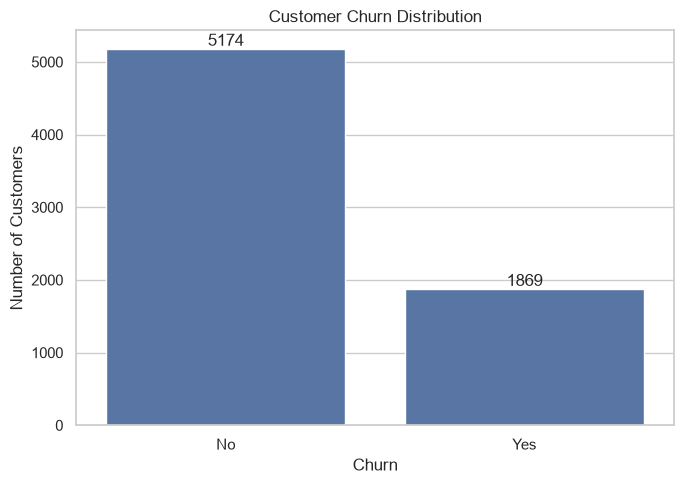

In [30]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="Churn", order=["No", "Yes"])

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

ANALYZE CHURN BY CONTRACT TYPE
This is one of the most interesting relationships in the dataset.

In [ ]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
display(contract_churn.round(2))

#pd.crosstab() creates a table comparing two categorical variables.
#The parameter normalize="index" divides each row by that row's total, 
# producing percentages within each contract category.


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


What can we conclude?
Customers with month-to-month contracts have a much higher observed churn rate than customers with longer contracts.

But be careful: correlation does not prove causation.

We cannot conclude that switching a customer to a two-year contract would automatically reduce their churn probability by the difference shown.

Other factors, such as tenure, pricing and customer preferences, may contribute to the relationship.

VISUALIZE CONTRACT TYPE AND CHURN

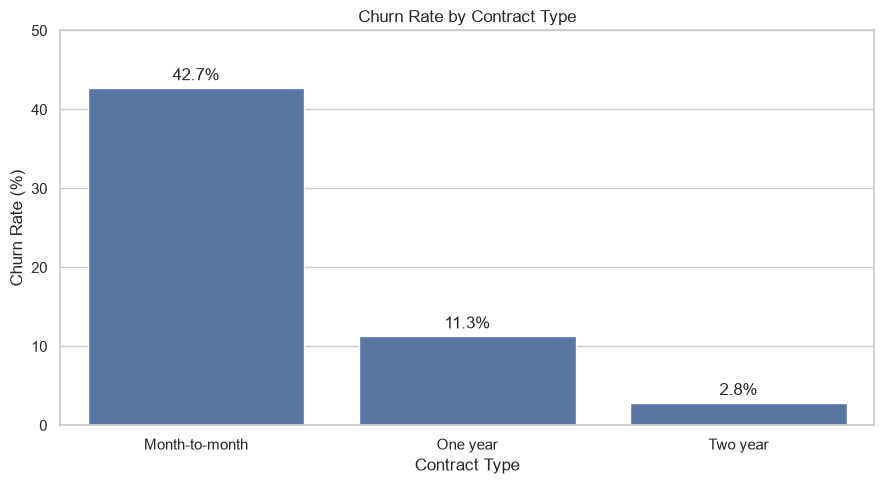

In [ ]:
contract_rates = (
    df.assign(ChurnFlag=df["Churn"].eq("Yes").astype(int))
      .groupby("Contract")["ChurnFlag"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(x=contract_rates.index, y=contract_rates.values)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(contract_rates.values):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

#This chart shows churn rates, not raw churn counts.
#Rates are more useful for comparing groups of different sizes.


ANALYZE TENURE
"tenure" is the number of months a customer has remained with the company.
We want to investigate whether newer customers are more likely to churn.

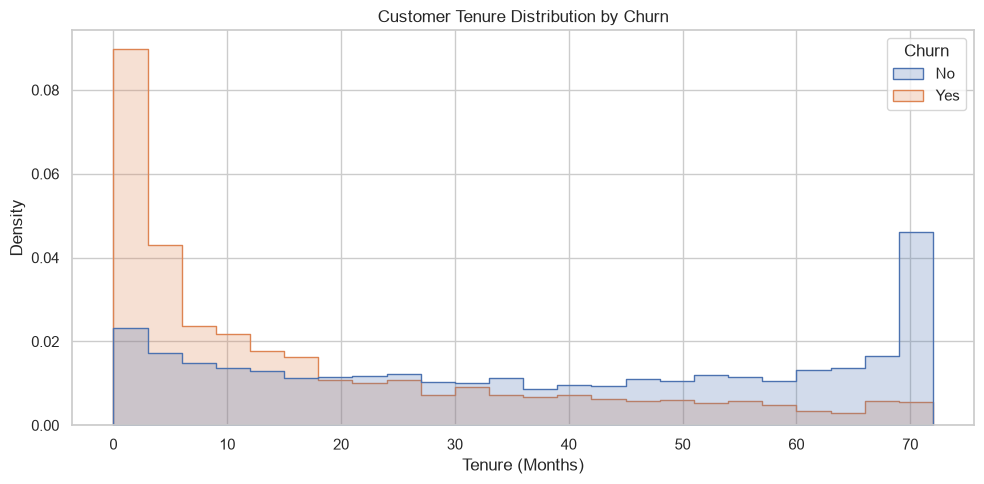

In [34]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=24,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Density")

plt.tight_layout()
plt.show()


Using common_norm=False makes the two groups' distributions individually normalized, so their shapes can be compared despite different group sizes.

Should observe that churned customers are more concentrated at shorter tenure values.

This is an association in the observed data, not proof that low tenure causes churn.

ANALYZE MONTHLY CHARGES

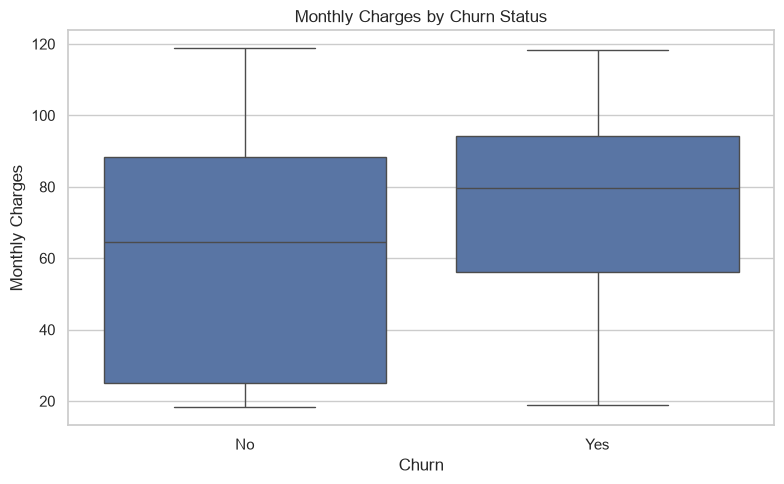

In [35]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    order=["No", "Yes"]
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()


ANALYZE NUMERICAL CORRELATION

What does correlation mean?
Pearson correlation measures the strength of a linear relationship between two variables.

Its value ranges from -1 to +1.
- +1 means a perfect positive linear relationship.
- 0 means no linear relationship.
- -1 means a perfect negative linear relationship.

For example, tenure and TotalCharges are expected to be positively correlated, because customers who have been subscribed longer generally accumulate more charges.

However, correlation does not measure every kind of relationship, and it does not establish causation.

Also, the correlation between a numerical feature and ChurnFlag is only an exploratory measure. It is not a substitute for model evaluation.

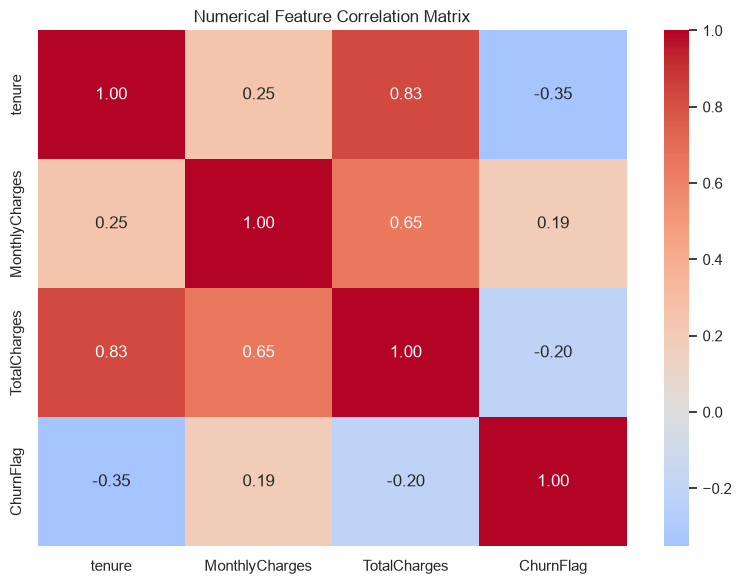

In [36]:
eda_numeric = df.copy()

eda_numeric["TotalCharges"] = pd.to_numeric( eda_numeric["TotalCharges"], errors="coerce")

eda_numeric["ChurnFlag"] = (eda_numeric["Churn"] == "Yes").astype(int)

numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "ChurnFlag"
]

correlation_matrix = (
    eda_numeric[numeric_columns].corr()
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.show()



# Exploratory Data Analysis — Key Findings

## Dataset Overview
- 7,043 customer records
- 21 original columns
- Target variable: Churn (Yes/No)

## Data Quality
- TotalCharges contains 11 blank/unconvertible values
- TotalCharges requires numeric conversion
- No duplicate customer IDs found

## Target Distribution
- No churn: 5,174 customers (73.46%)
- Churn: 1,869 customers (26.54%)
- Moderate class imbalance

## Observed Relationships
- Month-to-month customers have a higher churn rate
- Customers with shorter tenure appear more likely to churn
- Monthly charges may be associated with churn

## Modelling Implications
- Use stratified train/test splitting
- Fit preprocessing only on training data
- Compare against a majority-class baseline
- Evaluate precision, recall, F1 and ROC-AUC
- Investigate the 11 invalid TotalCharges values
- Avoid treating customerID as a predictive feature

## Limitations
- Observational data cannot establish causation
- This is a historical sample, not live customer data
- Model performance may not generalize to other telecom providers
